# Multi-session Variability

Cross-session, cross-animal view of the reward/variability relationship established in
`session_variability.ipynb`. Data comes from `scripts/build_variability_summary.py`, which
runs the same `clirb.native_dannce.build_session_variability` pipeline over every session
with dual SLEAP+DANNCE data and a behavior log across R4/R5/R6.

**Normalization note:** each rat's PCs come from its own independently-fit PCA, so raw PC
variability magnitudes are not directly comparable across rats (or even necessarily across
a rat's own sessions, if templates were refit). All cross-session/cross-rat comparisons
below use `var_pc{k}_norm` = variability divided by that session's own median variability --
i.e. "how variable relative to this session's typical rear", not absolute units. Single-
session analyses (as in `session_variability.ipynb`) don't need this; pooling across
sessions/rats does.

1. Rewarded vs unrewarded variability -- pooled and per rat.
2. Variability vs. rears since last reward -- per rat, overlaid.
3. Per-session trend across the training timeline, per rat.

In [1]:
import sys, os
sys.path.insert(0, '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, wilcoxon

%matplotlib inline

df = pd.read_csv('data/variability_summary/per_rear.csv')
df['run_idx'] = df['session'].str.rsplit('_', n=1).str[-1].astype(int)

# Session-relative normalization -- see markdown note above.
for k in (1, 2, 3):
    col = f'var_pc{k}'
    df[f'{col}_norm'] = df[col] / df.groupby(['rat', 'session'])[col].transform('median')

RATS = sorted(df['rat'].unique())
RAT_COLOR = {'R4': '#1f77b4', 'R5': '#ff7f0e', 'R6': '#2ca02c'}

# NOTE: df['session'].nunique() alone undercounts -- the same calendar-date
# session name (e.g. '2026_06_11_1') recurs across different rats, since all
# three run on the same day. Total distinct sessions = distinct (rat, session).
n_sessions_total = df[['rat', 'session']].drop_duplicates().shape[0]

print(f"{len(df)} rear-rows across {n_sessions_total} sessions, "
      f"{ {r: df[df.rat==r]['session'].nunique() for r in RATS} } sessions/rat")
print(f"date range {df['session_date'].min()} .. {df['session_date'].max()}")
print(f"overall reward rate: {df['is_rewarded'].mean():.1%} of rears")


def date_xticks(ax, dates, positions=None, max_ticks=10, rotation=45):
    """Evenly-spaced x positions (so calendar gaps don't distort the trend
    line) but tick LABELS show actual session dates, thinned to max_ticks."""
    if positions is None:
        positions = np.arange(len(dates))
    step = max(1, len(positions) // max_ticks)
    idx = list(range(0, len(positions), step))
    if idx[-1] != len(positions) - 1:
        idx.append(len(positions) - 1)
    ax.set_xticks([positions[i] for i in idx])
    ax.set_xticklabels([dates[i] for i in idx], rotation=rotation, ha='right', fontsize=7)


15772 rear-rows across 127 sessions, {'R4': 42, 'R5': 49, 'R6': 36} sessions/rat
date range 2026-06-11 .. 2026-09-11
overall reward rate: 33.7% of rears


## 1. Rewarded vs unrewarded variability -- pooled and per rat

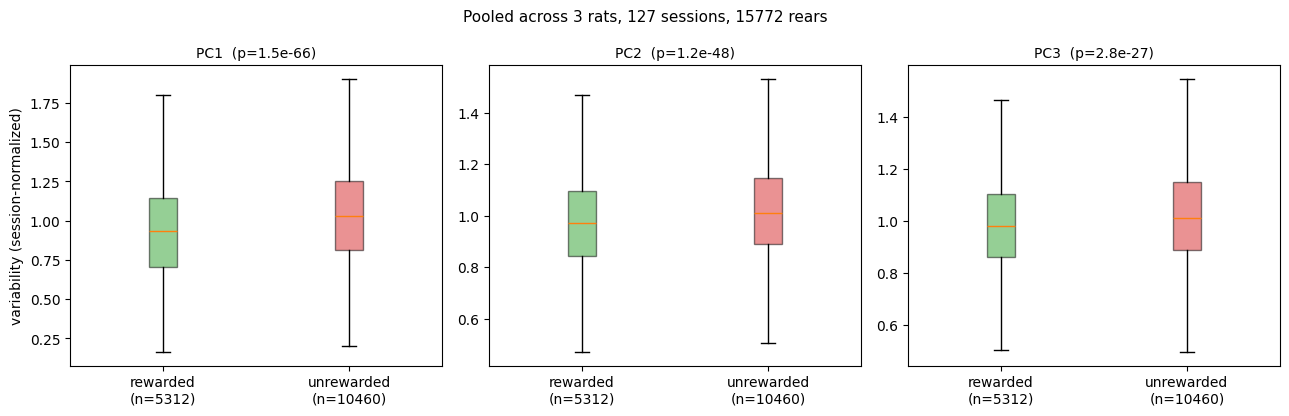

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for pidx, ax in enumerate(axes, start=1):
    col = f'var_pc{pidx}_norm'
    groups = [df.loc[df.is_rewarded, col], df.loc[~df.is_rewarded, col]]
    bp = ax.boxplot(groups, tick_labels=[f'rewarded\n(n={len(groups[0])})',
                                         f'unrewarded\n(n={len(groups[1])})'],
                    patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], ['#2ca02c', '#d62728']):
        patch.set_facecolor(color); patch.set_alpha(0.5)
    stat, p = mannwhitneyu(*groups)
    ax.set_title(f'PC{pidx}  (p={p:.1e})', fontsize=10)
    if pidx == 1:
        ax.set_ylabel('variability (session-normalized)')
fig.suptitle(f'Pooled across {df.rat.nunique()} rats, {n_sessions_total} sessions, '
            f'{len(df)} rears', fontsize=11)
fig.tight_layout()
plt.show()


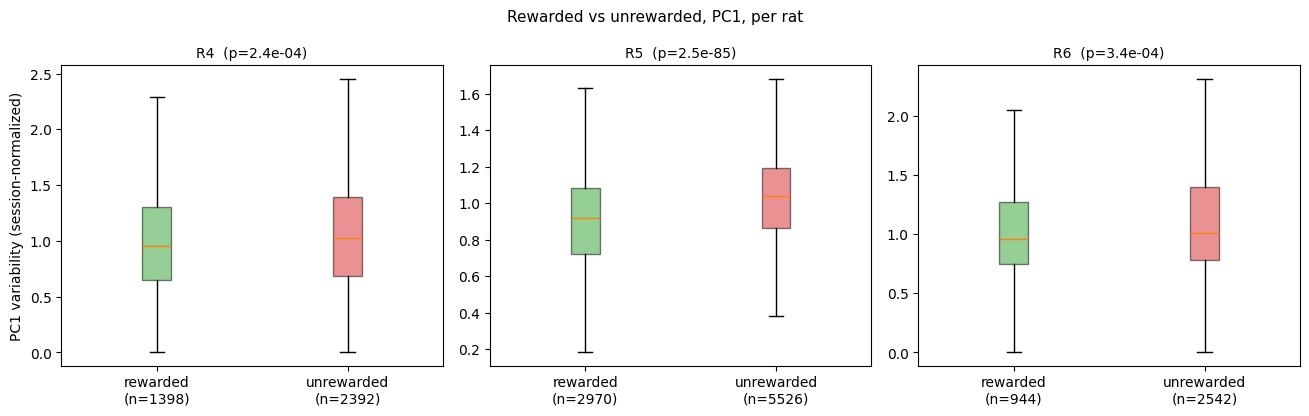

In [3]:
fig, axes = plt.subplots(1, len(RATS), figsize=(4.4 * len(RATS), 4.2), sharey=False)
for ax, rat in zip(axes, RATS):
    sub = df[df.rat == rat]
    groups = [sub.loc[sub.is_rewarded, 'var_pc1_norm'], sub.loc[~sub.is_rewarded, 'var_pc1_norm']]
    bp = ax.boxplot(groups, tick_labels=[f'rewarded\n(n={len(groups[0])})',
                                         f'unrewarded\n(n={len(groups[1])})'],
                    patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], ['#2ca02c', '#d62728']):
        patch.set_facecolor(color); patch.set_alpha(0.5)
    stat, p = mannwhitneyu(*groups)
    ax.set_title(f'{rat}  (p={p:.1e})', fontsize=10)
axes[0].set_ylabel('PC1 variability (session-normalized)')
fig.suptitle('Rewarded vs unrewarded, PC1, per rat', fontsize=11)
fig.tight_layout()
plt.show()


## 2. Variability vs. rears since last reward, per rat

Same binned "recovery" view as `session_variability.ipynb` section 3c, overlaid per rat to
check whether the shape (variability climbing the longer it's been since a reward) is
consistent across animals rather than driven by one rat/session.

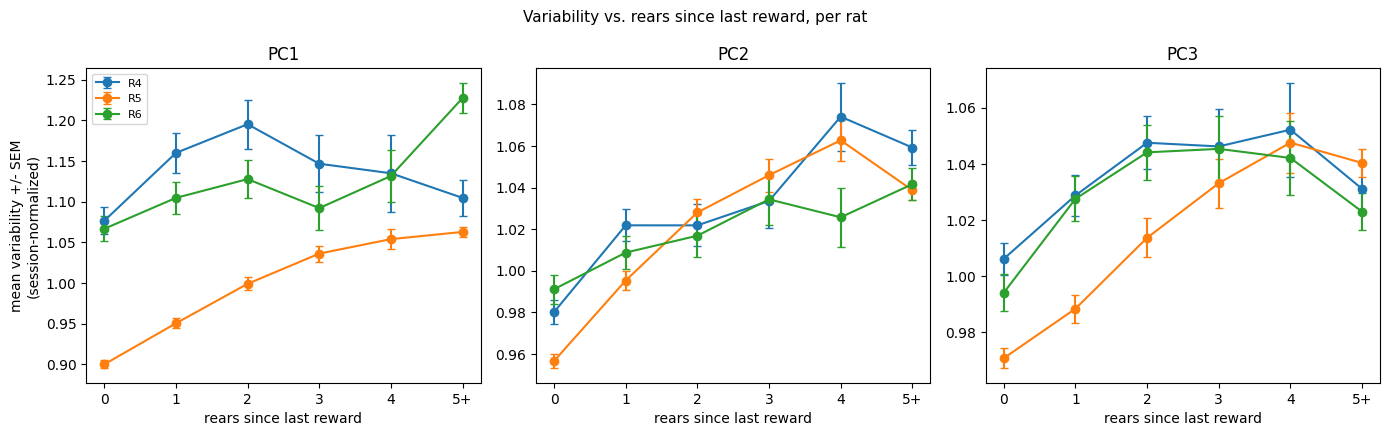

In [4]:
BIN_EDGES = [0, 1, 2, 3, 4, 5, np.inf]
BIN_LABELS = ['0', '1', '2', '3', '4', '5+']

after = df[df.rears_since_reward >= 0].copy()
after['bin'] = np.digitize(after['rears_since_reward'], BIN_EDGES[1:-1], right=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True)
for pidx, ax in enumerate(axes, start=1):
    col = f'var_pc{pidx}_norm'
    for rat in RATS:
        sub = after[after.rat == rat]
        means = [sub.loc[sub.bin == b, col].mean() for b in range(len(BIN_LABELS))]
        sems = [sub.loc[sub.bin == b, col].sem() for b in range(len(BIN_LABELS))]
        ax.errorbar(range(len(BIN_LABELS)), means, yerr=sems, marker='o', capsize=3,
                   color=RAT_COLOR[rat], label=rat)
    ax.set_xticks(range(len(BIN_LABELS)))
    ax.set_xticklabels(BIN_LABELS)
    ax.set_xlabel('rears since last reward')
    ax.set_title(f'PC{pidx}')
    if pidx == 1:
        ax.set_ylabel('mean variability +/- SEM\n(session-normalized)')
axes[0].legend(fontsize=8)
fig.suptitle('Variability vs. rears since last reward, per rat', fontsize=11)
fig.tight_layout()
plt.show()


## 3. Per-session trend across the training timeline

Top row: mean **raw** PC1 variability per session, per rat -- deliberately NOT
session-normalized here, since normalizing by a session's own median would remove exactly
the between-session drift this panel is meant to show. Caveat: templates are refit
occasionally per rat (non-monotonically), which can shift the PCA basis and introduce a
scale discontinuity unrelated to behavior -- read within-stretch trends, not absolute
cross-stretch jumps.

Bottom row: the reward effect per session (mean unrewarded - mean rewarded PC1
variability, session-normalized -- this comparison IS meant to be cross-session/cross-rat
comparable). Does reward's tightening effect on variability grow, shrink, or stay flat as
training progresses?

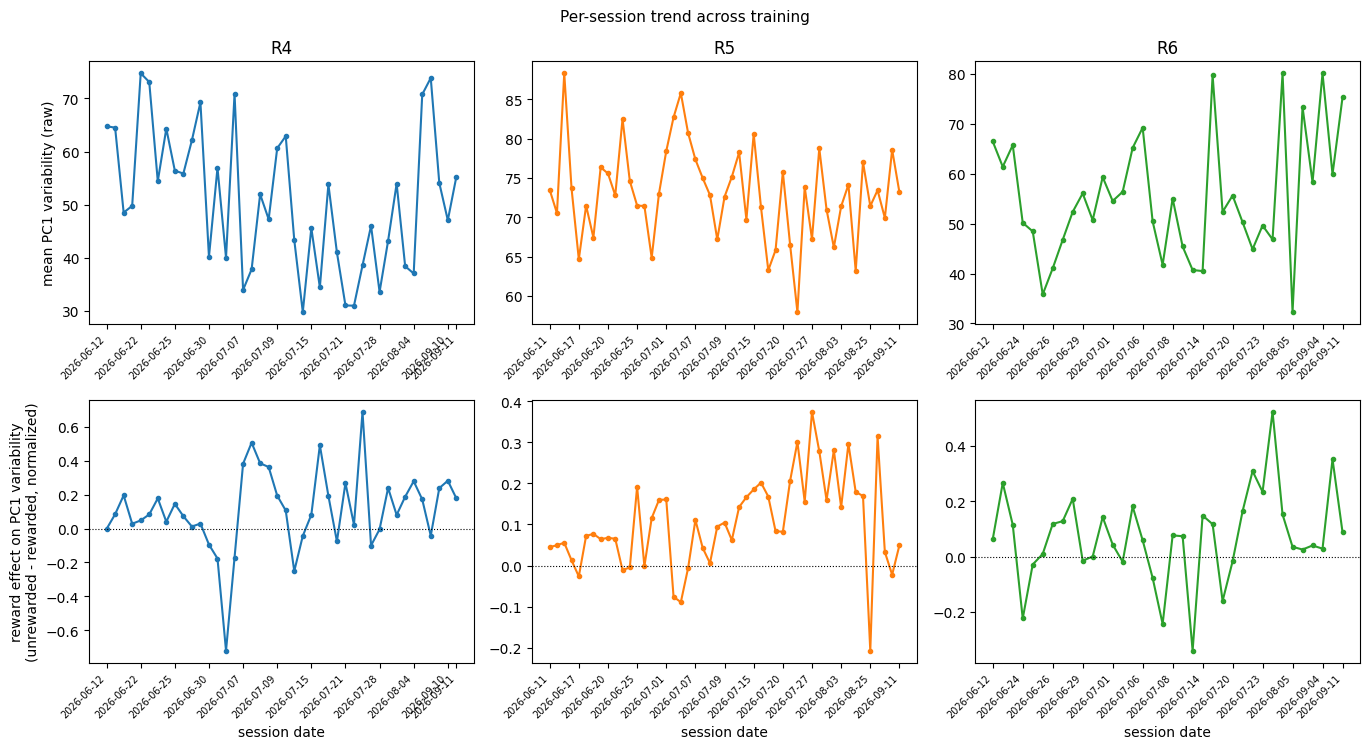

In [5]:
sessions_meta = (df[['rat', 'session', 'session_date', 'run_idx']]
                .drop_duplicates()
                .sort_values(['rat', 'session_date', 'run_idx'])
                .reset_index(drop=True))
sessions_meta['session_order'] = sessions_meta.groupby('rat').cumcount()

rows = []
for (rat, session), g in df.groupby(['rat', 'session']):
    r = g.loc[g.is_rewarded, 'var_pc1_norm']
    u = g.loc[~g.is_rewarded, 'var_pc1_norm']
    rows.append(dict(rat=rat, session=session,
                     mean_var_pc1_raw=g['var_pc1'].mean(),
                     reward_effect_pc1_norm=(u.mean() - r.mean()) if len(r) and len(u) else np.nan,
                     n_rears=len(g)))
per_session = pd.DataFrame(rows).merge(sessions_meta, on=['rat', 'session'])

fig, axes = plt.subplots(2, len(RATS), figsize=(4.6 * len(RATS), 7.6), sharex=False)
for col_i, rat in enumerate(RATS):
    sub = per_session[per_session.rat == rat].sort_values('session_order')
    dates = sub['session_date'].tolist()
    axes[0, col_i].plot(sub.session_order, sub.mean_var_pc1_raw, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    axes[0, col_i].set_title(rat)
    date_xticks(axes[0, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].plot(sub.session_order, sub.reward_effect_pc1_norm, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    axes[1, col_i].axhline(0.0, color='k', lw=0.8, ls=':')
    date_xticks(axes[1, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].set_xlabel('session date')
axes[0, 0].set_ylabel('mean PC1 variability (raw)')
axes[1, 0].set_ylabel('reward effect on PC1 variability\n(unrewarded - rewarded, normalized)')
fig.suptitle('Per-session trend across training', fontsize=11)
fig.tight_layout()
plt.show()


### 3b. Per-session trend, template-matched rears only (PC1 &amp; PC2)

Fig. 9 above averages over EVERY detected rear in a session, matched or not. This version
filters to `is_matched` (standard bounds) first, so each point is the mean variability of
only the rears that actually looked like the trained motif -- a cleaner read on the animal's
matched-behavior variability over training, not diluted by however many unmatched rears
happened that day. Raw units per rat (not session-normalized), same caveat as Fig. 9's top
row: a template refit can shift the scale within a rat's own series.

127/127 sessions have >=1 matched rear (0 sessions have none and are absent below, not padded)


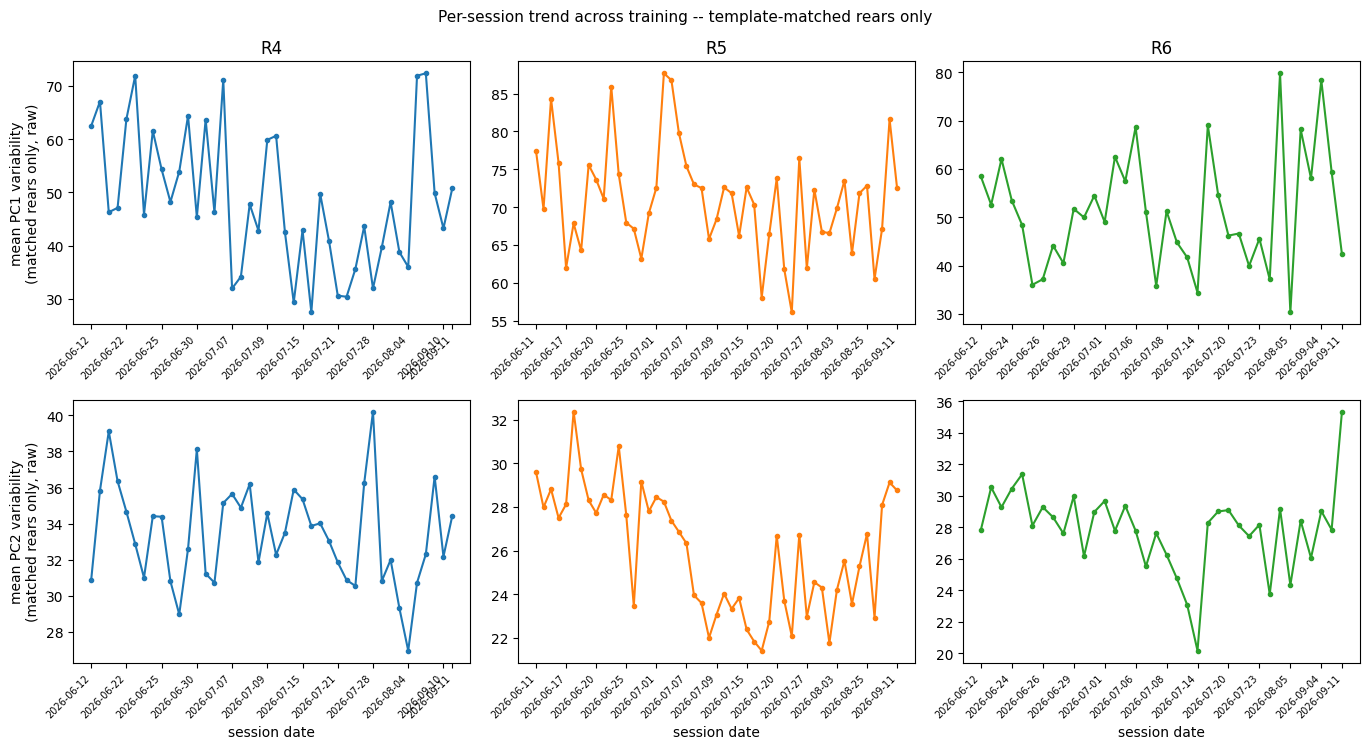

In [6]:
matched_df = df[df.is_matched]

rows = []
for (rat, session), g in matched_df.groupby(['rat', 'session']):
    rows.append(dict(rat=rat, session=session,
                     mean_var_pc1=g['var_pc1'].mean(),
                     mean_var_pc2=g['var_pc2'].mean(),
                     n_matched=len(g)))
per_session_matched = pd.DataFrame(rows).merge(sessions_meta, on=['rat', 'session'])

n_missing = per_session.shape[0] - per_session_matched.shape[0]
print(f'{len(per_session_matched)}/{per_session.shape[0]} sessions have >=1 matched rear '
     f'({n_missing} sessions have none and are absent below, not padded)')

fig, axes = plt.subplots(2, len(RATS), figsize=(4.6 * len(RATS), 7.6), sharex=False)
for col_i, rat in enumerate(RATS):
    sub = per_session_matched[per_session_matched.rat == rat].sort_values('session_order')
    dates = sub['session_date'].tolist()
    axes[0, col_i].plot(sub.session_order, sub.mean_var_pc1, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    axes[0, col_i].set_title(rat)
    date_xticks(axes[0, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].plot(sub.session_order, sub.mean_var_pc2, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    date_xticks(axes[1, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].set_xlabel('session date')
axes[0, 0].set_ylabel('mean PC1 variability\n(matched rears only, raw)')
axes[1, 0].set_ylabel('mean PC2 variability\n(matched rears only, raw)')
fig.suptitle('Per-session trend across training -- template-matched rears only', fontsize=11)
fig.tight_layout()
plt.show()


### 3c. Same trends, restricted to sessions before 2026-08-07

All three rats got a new template right around 2026-08-05/08-06 (see &sect;6 below), which
also coincides with the online SLEAP corrector network being disabled session-wide from
2026-07-29 onward. Reproduces Fig. 9 and Fig. 9b restricted to sessions before that
changeover -- the training trend without that later regime mixed in. Session x-positions
are the same `session_order` as above (evenly spaced, not reassigned), which stay
contiguous from 0 since only later sessions are dropped.

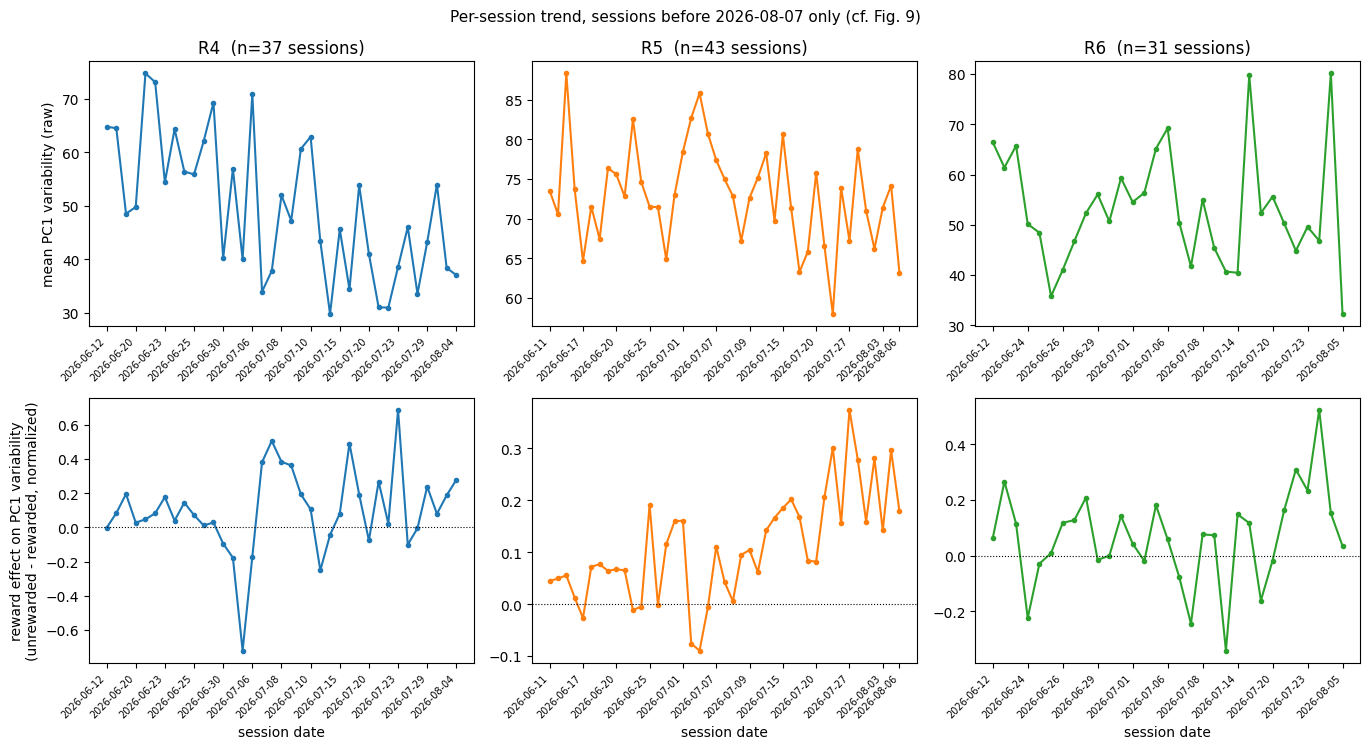

In [7]:
CUTOFF_DATE = '2026-08-07'

per_session_early = per_session[per_session.session_date < CUTOFF_DATE]

fig, axes = plt.subplots(2, len(RATS), figsize=(4.6 * len(RATS), 7.6), sharex=False)
for col_i, rat in enumerate(RATS):
    sub = per_session_early[per_session_early.rat == rat].sort_values('session_order')
    dates = sub['session_date'].tolist()
    axes[0, col_i].plot(sub.session_order, sub.mean_var_pc1_raw, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    axes[0, col_i].set_title(f'{rat}  (n={len(sub)} sessions)')
    date_xticks(axes[0, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].plot(sub.session_order, sub.reward_effect_pc1_norm, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    axes[1, col_i].axhline(0.0, color='k', lw=0.8, ls=':')
    date_xticks(axes[1, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].set_xlabel('session date')
axes[0, 0].set_ylabel('mean PC1 variability (raw)')
axes[1, 0].set_ylabel('reward effect on PC1 variability\n(unrewarded - rewarded, normalized)')
fig.suptitle(f'Per-session trend, sessions before {CUTOFF_DATE} only (cf. Fig. 9)', fontsize=11)
fig.tight_layout()
plt.show()


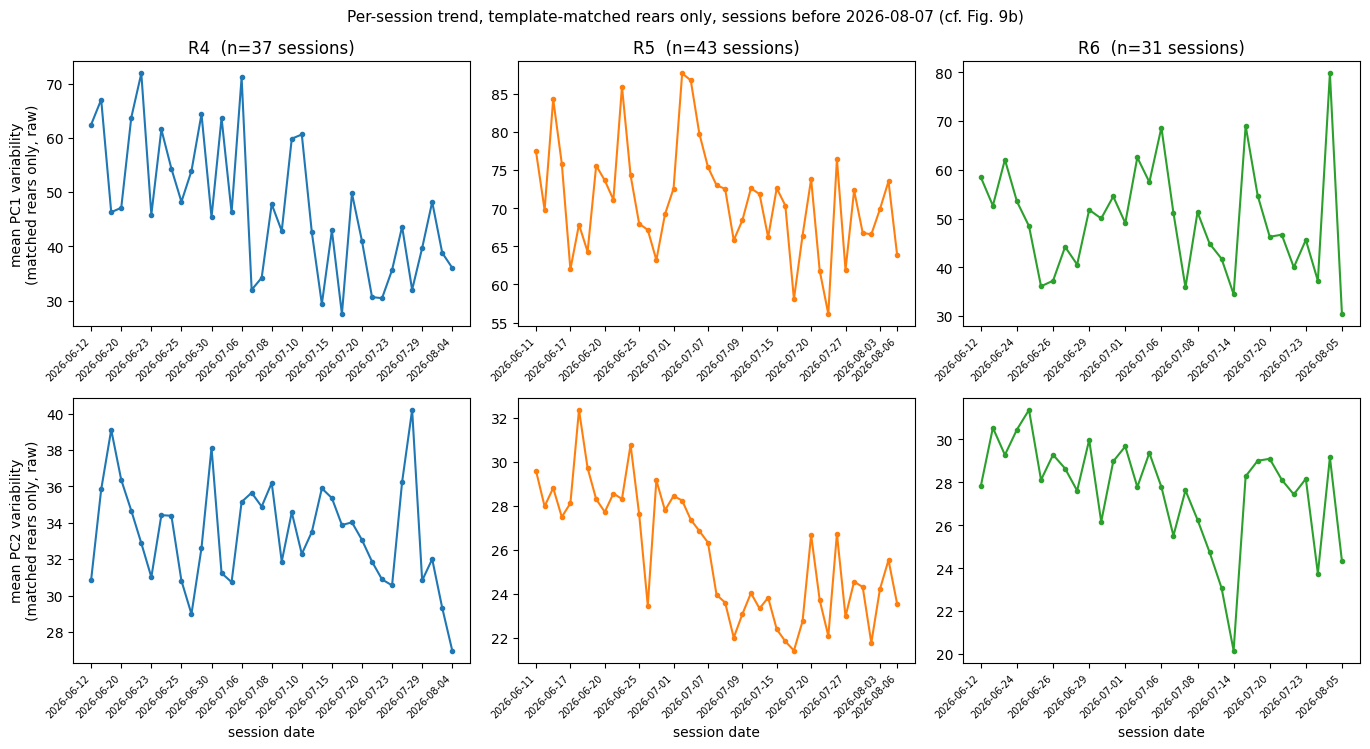

In [8]:
per_session_matched_early = per_session_matched[per_session_matched.session_date < CUTOFF_DATE]

fig, axes = plt.subplots(2, len(RATS), figsize=(4.6 * len(RATS), 7.6), sharex=False)
for col_i, rat in enumerate(RATS):
    sub = per_session_matched_early[per_session_matched_early.rat == rat].sort_values('session_order')
    dates = sub['session_date'].tolist()
    axes[0, col_i].plot(sub.session_order, sub.mean_var_pc1, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    axes[0, col_i].set_title(f'{rat}  (n={len(sub)} sessions)')
    date_xticks(axes[0, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].plot(sub.session_order, sub.mean_var_pc2, marker='o', ms=3,
                        color=RAT_COLOR[rat])
    date_xticks(axes[1, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].set_xlabel('session date')
axes[0, 0].set_ylabel('mean PC1 variability\n(matched rears only, raw)')
axes[1, 0].set_ylabel('mean PC2 variability\n(matched rears only, raw)')
fig.suptitle(f'Per-session trend, template-matched rears only, '
            f'sessions before {CUTOFF_DATE} (cf. Fig. 9b)', fontsize=11)
fig.tight_layout()
plt.show()


## 4. Template-like rears: rewarded vs. merely close to the template

Recommendation #2: is section 1's effect really about reward, or just about being close to
the trained motif? `is_template_like` replays the matching rule with `bounds_to_use`
widened by 1.25x (same `accepted_errors`) -- a superset of `is_matched`. Within that
broader "close enough" population, split by the real reward label, pooled and per rat.

8980/15772 rears are template-like (1.25x bounds); 4731 rewarded, 4249 unrewarded


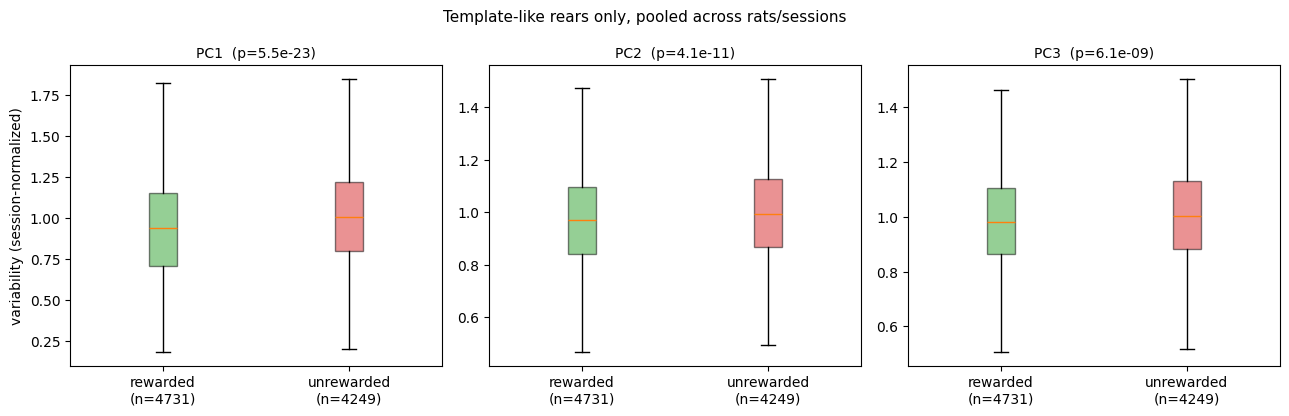

In [9]:
tl = df[df.is_template_like]
print(f'{len(tl)}/{len(df)} rears are template-like (1.25x bounds); '
      f'{int(tl.is_rewarded.sum())} rewarded, {int((~tl.is_rewarded).sum())} unrewarded')

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for pidx, ax in enumerate(axes, start=1):
    col = f'var_pc{pidx}_norm'
    groups = [tl.loc[tl.is_rewarded, col], tl.loc[~tl.is_rewarded, col]]
    bp = ax.boxplot(groups, tick_labels=[f'rewarded\n(n={len(groups[0])})',
                                         f'unrewarded\n(n={len(groups[1])})'],
                    patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], ['#2ca02c', '#d62728']):
        patch.set_facecolor(color); patch.set_alpha(0.5)
    stat, p = mannwhitneyu(*groups)
    ax.set_title(f'PC{pidx}  (p={p:.1e})', fontsize=10)
    if pidx == 1:
        ax.set_ylabel('variability (session-normalized)')
fig.suptitle('Template-like rears only, pooled across rats/sessions', fontsize=11)
fig.tight_layout()
plt.show()


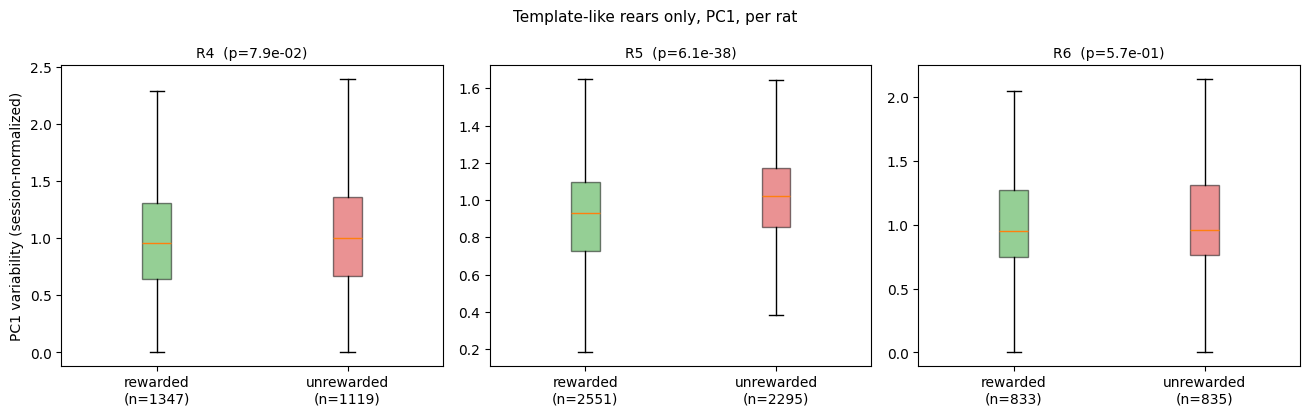

template-like-only, session-level: n=127 sessions with both rewarded and unrewarded template-like rears
  mean effect (unrewarded - rewarded) = 0.043, positive in 77/127 sessions, Wilcoxon p=8.46e-04


In [10]:
fig, axes = plt.subplots(1, len(RATS), figsize=(4.4 * len(RATS), 4.2), sharey=False)
for ax, rat in zip(axes, RATS):
    sub = tl[tl.rat == rat]
    groups = [sub.loc[sub.is_rewarded, 'var_pc1_norm'], sub.loc[~sub.is_rewarded, 'var_pc1_norm']]
    bp = ax.boxplot(groups, tick_labels=[f'rewarded\n(n={len(groups[0])})',
                                         f'unrewarded\n(n={len(groups[1])})'],
                    patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], ['#2ca02c', '#d62728']):
        patch.set_facecolor(color); patch.set_alpha(0.5)
    stat, p = mannwhitneyu(*groups)
    ax.set_title(f'{rat}  (p={p:.1e})', fontsize=10)
axes[0].set_ylabel('PC1 variability (session-normalized)')
fig.suptitle('Template-like rears only, PC1, per rat', fontsize=11)
fig.tight_layout()
plt.show()

# Session-level rigor check, restricted to template-like rears (mirrors section 04
# of the report for the full population).
rows = []
for (rat, session), g in tl.groupby(['rat', 'session']):
    r = g.loc[g.is_rewarded, 'var_pc1_norm']
    u = g.loc[~g.is_rewarded, 'var_pc1_norm']
    if len(r) and len(u):
        rows.append(dict(rat=rat, effect=u.mean() - r.mean()))
tl_eff = pd.DataFrame(rows)
stat, p = wilcoxon(tl_eff.effect)
print(f'template-like-only, session-level: n={len(tl_eff)} sessions with both '
      f'rewarded and unrewarded template-like rears')
print(f'  mean effect (unrewarded - rewarded) = {tl_eff.effect.mean():.3f}, '
      f'positive in {int((tl_eff.effect > 0).sum())}/{len(tl_eff)} sessions, '
      f'Wilcoxon p={p:.2e}')


## 5. Learning across training: first 10 vs. last 10 matches per session

Restricted to sessions with >= 20 MATCHED rears (standard bounds, `is_matched`) -- enough
matches in one session for a "first 10" and "last 10" to be disjoint and each be a
reasonably-sized group. For each such session: the first 10 and last 10 matched rears
(chronological order within the session) are each treated as a fixed group, and scored
with the same stack-and-std-over-time variability measure used everywhere else in this
project, just applied to a fixed 10-rear group instead of a rolling window of 5. Plotted
against actual session date, per rat, to see whether within-session dynamics (first-10 vs
last-10) themselves change over the course of training.

106 sessions with >= 20 matches, by rat: {'R4': 35, 'R5': 45, 'R6': 26}


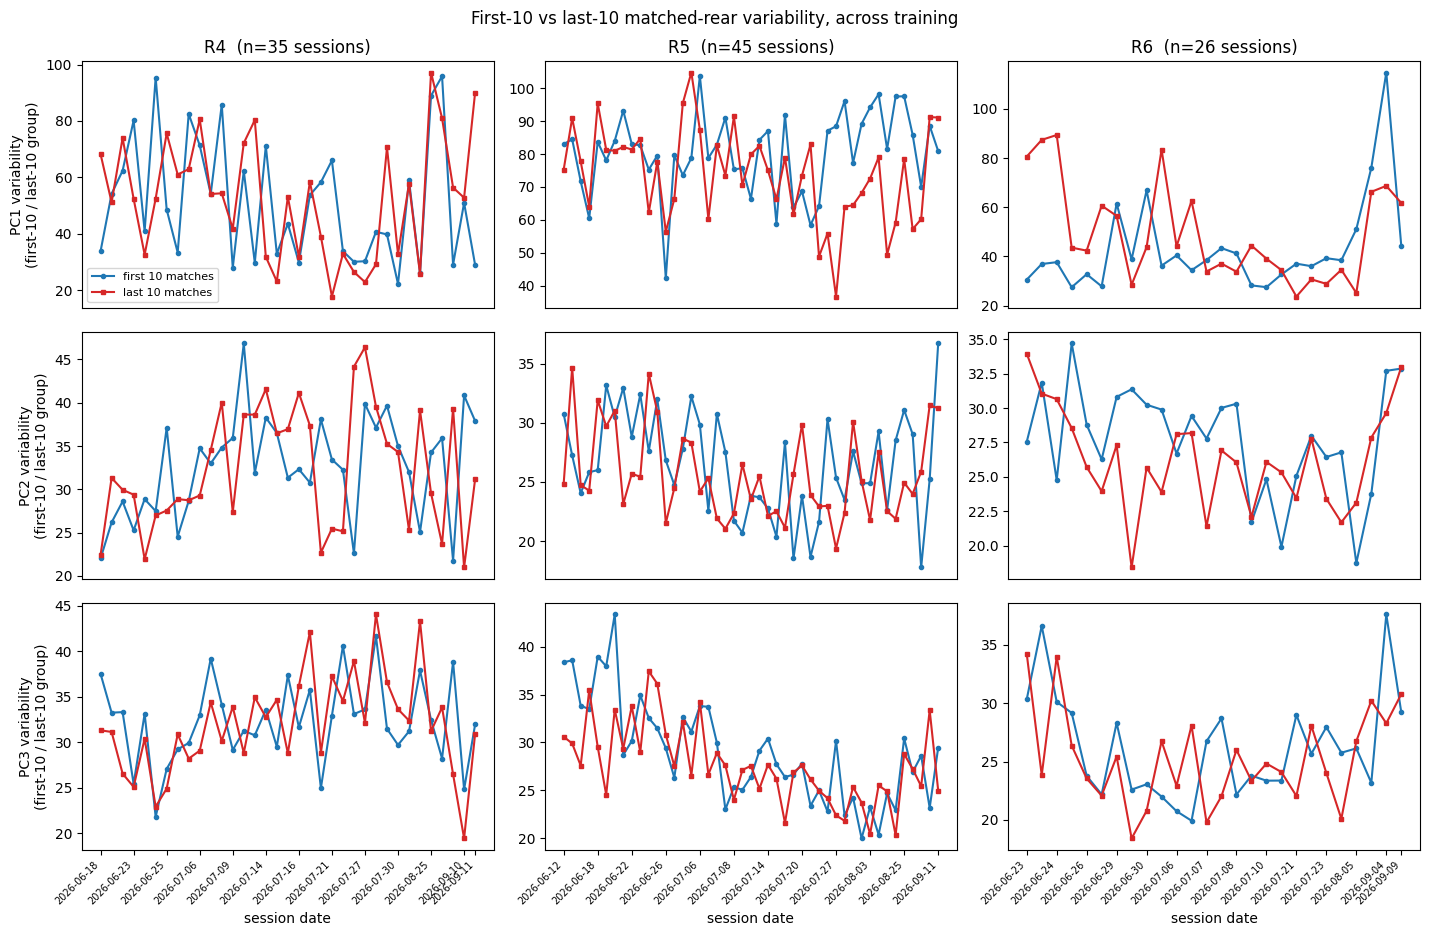


first10 - last10, PC1, paired across 106 sessions: mean=0.77, positive (first > last) in 59/106 sessions, Wilcoxon p=4.35e-01

variability vs. training progress (Spearman rank correlation, per rat/PC):
  R4 PC1: rho=-0.23, p=1.87e-01
  R4 PC2: rho=+0.36, p=3.37e-02  <-- p<0.05
  R4 PC3: rho=+0.25, p=1.49e-01
  R5 PC1: rho=-0.10, p=5.20e-01
  R5 PC2: rho=-0.32, p=2.94e-02  <-- p<0.05
  R5 PC3: rho=-0.72, p=1.86e-08  <-- p<0.05
  R6 PC1: rho=-0.21, p=2.95e-01
  R6 PC2: rho=-0.31, p=1.21e-01
  R6 PC3: rho=+0.05, p=8.10e-01


In [11]:
learn = pd.read_csv('data/variability_summary/per_session_learning.csv')
learn['run_idx'] = learn['session'].str.rsplit('_', n=1).str[-1].astype(int)
learn = learn.sort_values(['rat', 'session_date', 'run_idx']).reset_index(drop=True)
learn['session_order'] = learn.groupby('rat').cumcount()

print(f'{len(learn)} sessions with >= 20 matches, by rat: '
      f'{learn.groupby("rat").size().to_dict()}')

fig, axes = plt.subplots(3, len(RATS), figsize=(4.8 * len(RATS), 9.5), sharex=False)
for col_i, rat in enumerate(RATS):
    sub = learn[learn.rat == rat]
    dates = sub['session_date'].tolist()
    for pidx in range(1, 4):
        ax = axes[pidx - 1, col_i]
        ax.plot(sub.session_order, sub[f'first10_var_pc{pidx}'], marker='o', ms=3,
               color='#1f77b4', label='first 10 matches')
        ax.plot(sub.session_order, sub[f'last10_var_pc{pidx}'], marker='s', ms=3,
               color='#d62728', label='last 10 matches')
        if pidx == 1:
            ax.set_title(f'{rat}  (n={len(sub)} sessions)')
        if col_i == 0:
            ax.set_ylabel(f'PC{pidx} variability\n(first-10 / last-10 group)')
        if pidx == 3:
            date_xticks(ax, dates, sub.session_order.tolist())
            ax.set_xlabel('session date')
        else:
            ax.set_xticks([])
        if pidx == 1 and col_i == 0:
            ax.legend(fontsize=8)
fig.suptitle('First-10 vs last-10 matched-rear variability, across training', fontsize=12)
fig.tight_layout()
plt.show()

# Paired check: within a session, is the first-10 group reliably more/less variable
# than the last-10 group? (paired across sessions, PC1, pooled over rats)
diff = (learn['first10_var_pc1'] - learn['last10_var_pc1'])
stat, p = wilcoxon(diff)
print(f'\nfirst10 - last10, PC1, paired across {len(learn)} sessions: '
      f'mean={diff.mean():.2f}, positive (first > last) in '
      f'{int((diff > 0).sum())}/{len(learn)} sessions, Wilcoxon p={p:.2e}')

# A DIFFERENT question: regardless of first-vs-last, does matched-rear variability
# itself trend up or down across TRAINING (session order)? Average first10/last10
# per session as one training-progress point and rank-correlate against session order.
from scipy.stats import spearmanr
print('\nvariability vs. training progress (Spearman rank correlation, per rat/PC):')
for rat in RATS:
    sub = learn[learn.rat == rat].sort_values('session_order')
    for pidx in range(1, 4):
        overall = (sub[f'first10_var_pc{pidx}'] + sub[f'last10_var_pc{pidx}']) / 2
        rho, p = spearmanr(sub['session_order'], overall)
        flag = '  <-- p<0.05' if p < 0.05 else ''
        print(f'  {rat} PC{pidx}: rho={rho:+.2f}, p={p:.2e}{flag}')


## 6. Template evolution: how the templates and their bounds have changed

Independent of DANNCE/reward data -- pulls every session's own template file (which
`clirb.templates.load_template` resolves per-session, so it reflects whatever was actually
in effect at the time) and looks purely at the template curve and its acceptance band.
Templates are refined in place (same filename, e.g. `R4_template_1.npz`, can carry
different content at different points -- distinguished here by content hash, `_sha`), so
"distinct template" below means distinct CONTENT, not distinct filename. Computed over the
same session population as the rest of this notebook (163 sessions with dual data), not
every session that ever ran -- template refinements between two dual-data sessions would
be invisible here, so treat this as a lower bound on how much churn there really was.

In [12]:
from clirb import templates as tmpl

sessions_all = df[['rat', 'session', 'session_date']].drop_duplicates().sort_values(['rat', 'session_date'])

template_rows = []
for _, row in sessions_all.iterrows():
    t = tmpl.load_template(row['rat'], row['session'])
    if t is None:
        continue
    template_rows.append(dict(rat=row['rat'], session=row['session'], session_date=row['session_date'],
                              sha=t['_sha'], file=t['_file'],
                              template=t['template'][:, :2].copy(), bounds=t['bounds_to_use'][:, :2].copy()))
template_df = pd.DataFrame(template_rows)
print(f'{len(template_df)} sessions with a resolvable template; '
     f'{template_df.groupby("rat")["sha"].nunique().to_dict()} distinct template contents per rat')


127 sessions with a resolvable template; {'R4': 5, 'R5': 7, 'R6': 8} distinct template contents per rat


### 6a. Every distinct template used, in chronological order

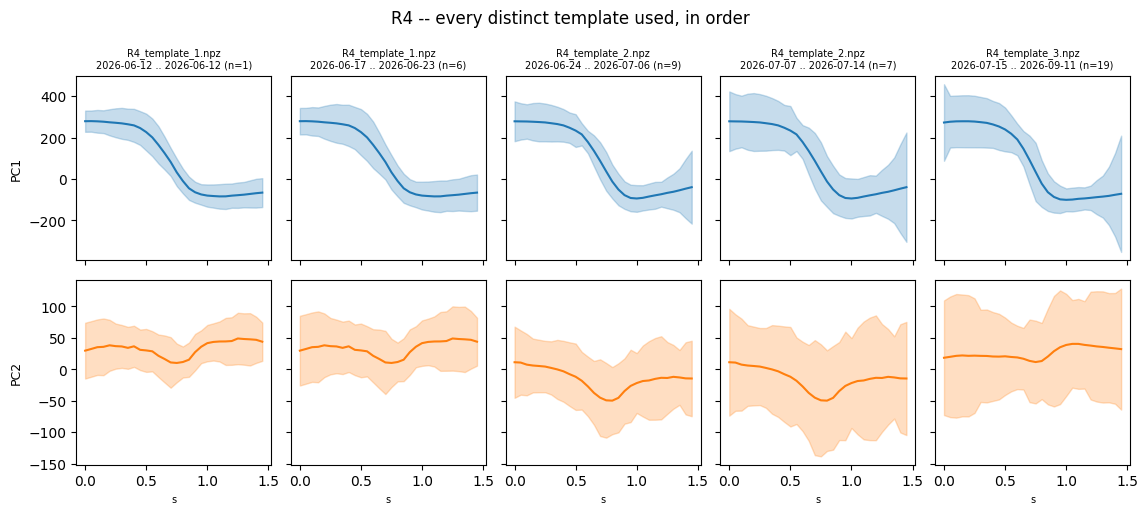

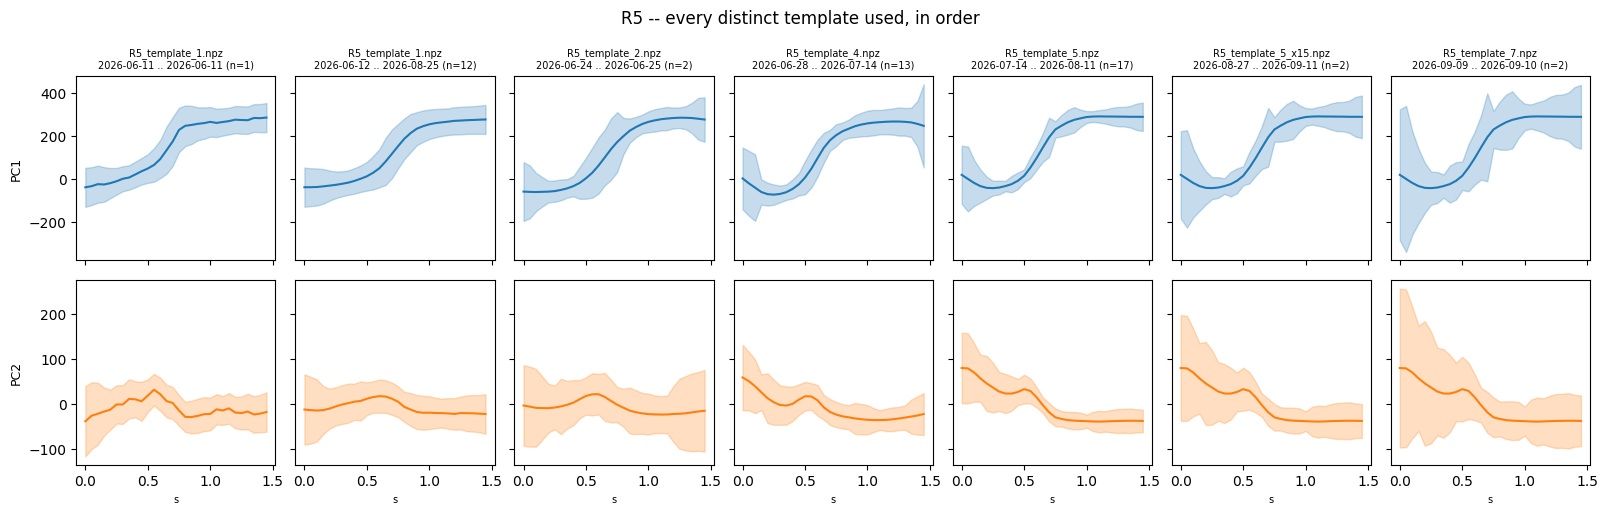

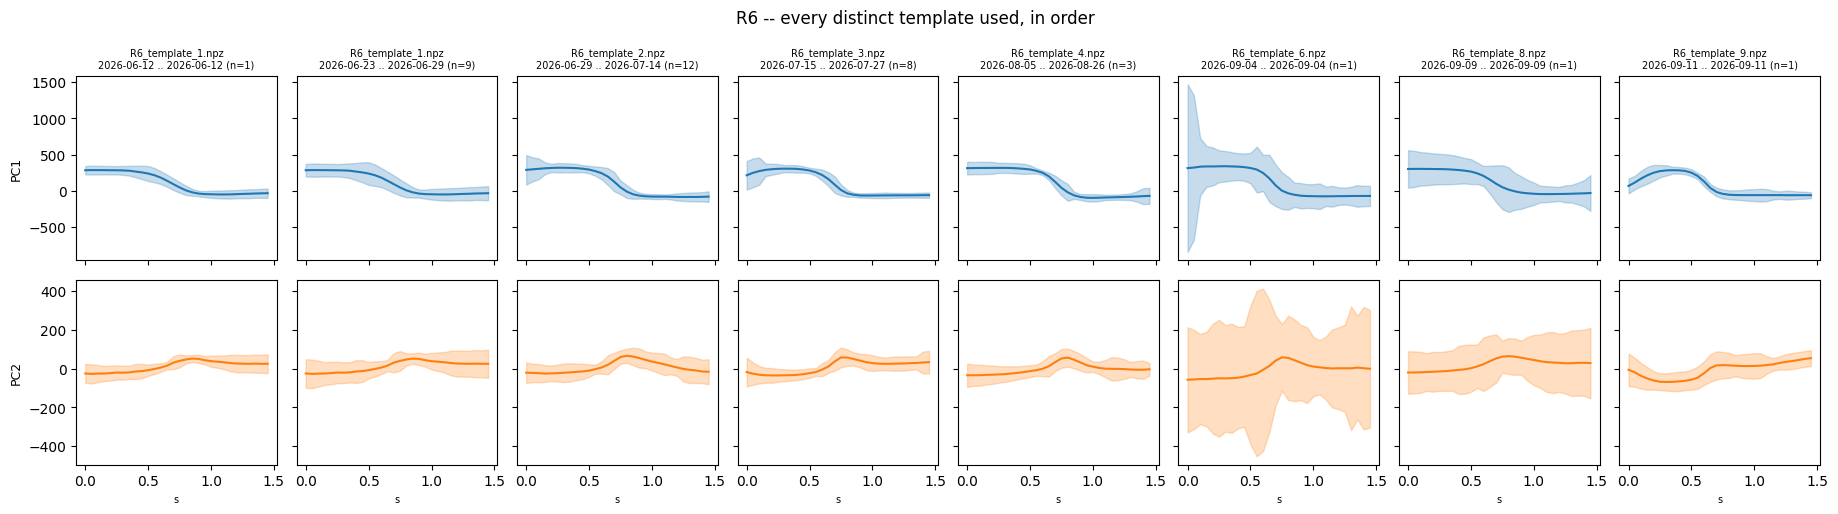

In [13]:
distinct = (template_df.sort_values('session_date')
           .groupby(['rat', 'sha'], as_index=False)
           .agg(file=('file', 'first'), first_date=('session_date', 'first'),
                last_date=('session_date', 'last'), n_sessions=('session', 'size'),
                template=('template', 'first'), bounds=('bounds', 'first')))
distinct = distinct.sort_values(['rat', 'first_date'])

t_axis_tmpl = np.arange(30) / 20.0  # template is 30 frames @ 20 Hz (the online rule's rate)
PC_COLOR = ['#1f77b4', '#ff7f0e']

for rat in RATS:
    d = distinct[distinct.rat == rat].reset_index(drop=True)
    n = len(d)
    fig, axes = plt.subplots(2, n, figsize=(2.3 * n, 5.2), sharex=True, sharey='row')
    for i, row in d.iterrows():
        for pidx, color in enumerate(PC_COLOR):
            ax = axes[pidx, i]
            center = row['template'][:, pidx]
            band = row['bounds'][:, pidx]
            ax.fill_between(t_axis_tmpl, center - band, center + band, color=color, alpha=0.25)
            ax.plot(t_axis_tmpl, center, color=color, lw=1.5)
            if pidx == 0:
                ax.set_title(f"{row['file']}\n{row['first_date']} .. {row['last_date']} "
                            f"(n={row['n_sessions']})", fontsize=7)
            if i == 0:
                ax.set_ylabel(f'PC{pidx + 1}', fontsize=9)
            if pidx == 1:
                ax.set_xlabel('s', fontsize=7)
    fig.suptitle(f'{rat} -- every distinct template used, in order', fontsize=12)
    fig.tight_layout()
    plt.show()


### 6b. Total acceptance-band width, per session, over time

Width at each timepoint = 2 &times; `bounds_to_use` (the full accepted band, both sides of
the template center), summed over all 30 timepoints -- per PC, per session. Plotted per
session (not per distinct template) so every refinement shows up as a step at the exact
session it took effect, even when the filename didn't change.

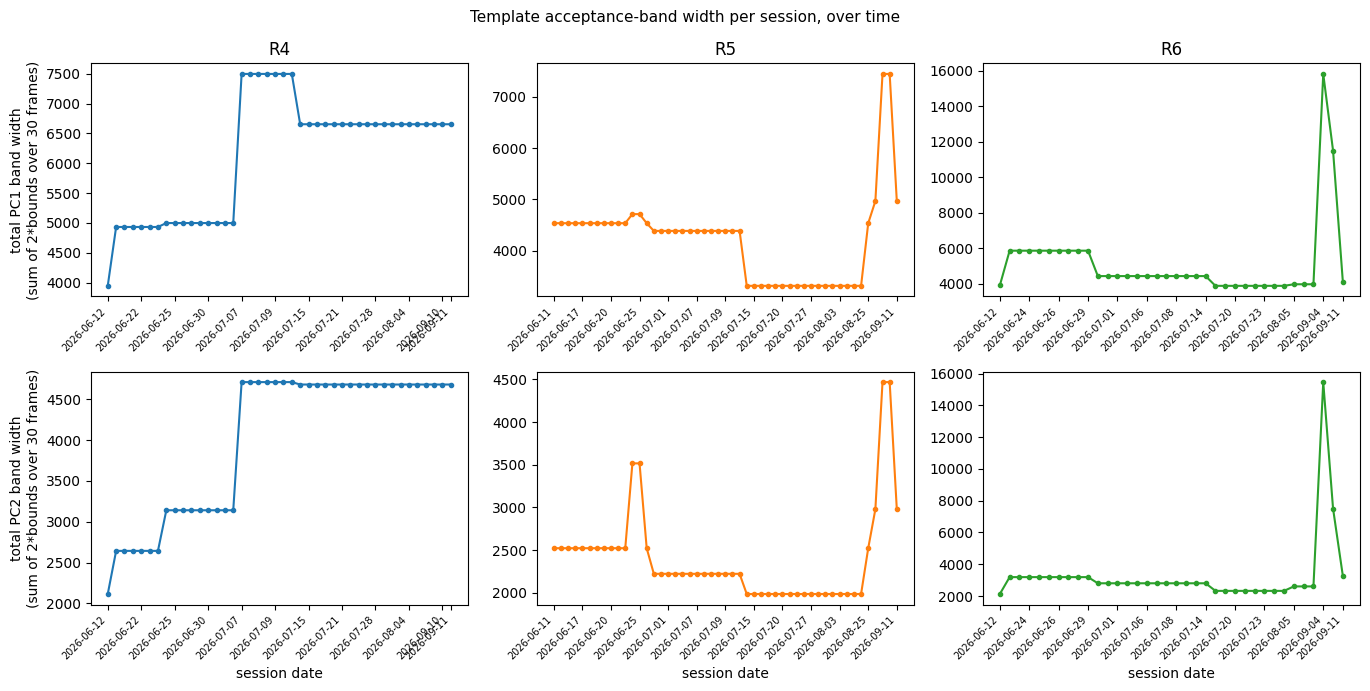

In [14]:
template_df['width_pc1'] = template_df['bounds'].apply(lambda b: 2 * b[:, 0].sum())
template_df['width_pc2'] = template_df['bounds'].apply(lambda b: 2 * b[:, 1].sum())

tmeta = template_df[['rat', 'session', 'session_date']].drop_duplicates().copy()
tmeta['run_idx'] = tmeta['session'].str.rsplit('_', n=1).str[-1].astype(int)
tmeta = tmeta.sort_values(['rat', 'session_date', 'run_idx']).reset_index(drop=True)
tmeta['session_order'] = tmeta.groupby('rat').cumcount()
template_df = template_df.merge(tmeta[['rat', 'session', 'session_order']], on=['rat', 'session'])

fig, axes = plt.subplots(2, len(RATS), figsize=(4.6 * len(RATS), 7), sharex=False)
for col_i, rat in enumerate(RATS):
    sub = template_df[template_df.rat == rat].sort_values('session_order')
    dates = sub['session_date'].tolist()
    axes[0, col_i].plot(sub.session_order, sub.width_pc1, marker='o', ms=3, color=RAT_COLOR[rat])
    axes[0, col_i].set_title(rat)
    date_xticks(axes[0, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].plot(sub.session_order, sub.width_pc2, marker='o', ms=3, color=RAT_COLOR[rat])
    date_xticks(axes[1, col_i], dates, sub.session_order.tolist())
    axes[1, col_i].set_xlabel('session date')
axes[0, 0].set_ylabel('total PC1 band width\n(sum of 2*bounds over 30 frames)')
axes[1, 0].set_ylabel('total PC2 band width\n(sum of 2*bounds over 30 frames)')
fig.suptitle('Template acceptance-band width per session, over time', fontsize=11)
fig.tight_layout()
plt.show()
